<a href="https://colab.research.google.com/github/rlaqhtjd-2026/group-8-surveying2/blob/main/02_%EA%B0%9C%EC%9D%B8%EB%B6%84%EC%84%9D/%EC%84%B8%EB%B6%80%EB%AA%A9%EC%A0%81(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

설치 및 초기화

In [ ]:
# 필요한 패키지 설치
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "-q", "install",
    "earthengine-api", "geemap", "pandas",
    "openpyxl", "ipywidgets", "koreanize-matplotlib"
])

import ee
import geemap
import pandas as pd
import numpy as np
import ipywidgets as widgets
import ipyleaflet
import traceback
import io
import requests
import math

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from PIL import Image

from pathlib import Path
from google.colab import files, output
from IPython.display import display, clear_output

import koreanize_matplotlib

# Colab에서 지도 위젯이 정상적으로 보이도록 설정
output.enable_custom_widget_manager()

# Google Earth Engine 프로젝트
PROJECT = "class-2026-508800"

# Sentinel-2 Level-2A 자료
COLLECTION_ID = "COPERNICUS/S2_SR_HARMONIZED"

# 분석 기간
START_DATE = "2026-05-01"
END_DATE = "2026-10-01"

# 전체 영상에 적용할 구름 비율 조건
MAX_CLOUD_PERCENT = 20.0

# NDCI-클로로필-a 회귀식
SLOPE = 191.688874
INTERCEPT = 23.757085

# 현재 채수지점 좌표
SITE_LON = 128.9523888889
SITE_LAT = 35.33525

# 수체 판별 기준
MNDWI_THRESHOLD = 0.18
NDWI_THRESHOLD = 0.08
MAX_NIR = 0.15

# 결과 저장 폴더
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

# Google Earth Engine 초기화
try:
    ee.Initialize(project=PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT)

# 채수지점
site_point = ee.Geometry.Point([SITE_LON, SITE_LAT])

# 채수지점 중심의 약 20km × 20km 분석 범위
lat_offset = 10.0 / 111.0
lon_offset = 10.0 / 90.7

roi = ee.Geometry.Rectangle([
    SITE_LON - lon_offset,
    SITE_LAT - lat_offset,
    SITE_LON + lon_offset,
    SITE_LAT + lat_offset
])

# 이전 계산 결과 초기화
analysis_cache = {}
saved_map_state = {}

print("초기화 완료")
print("기준: 현재 채수지점 좌표가 속한 20m 픽셀 1개")
print("버퍼 평균은 사용하지 않습니다.")
print(f"회귀식: Chl-a = {SLOPE} × NDCI + {INTERCEPT}")
print("농도·편차 단위: mg/m³")

초기화 완료
기준: 현재 채수지점 좌표가 속한 20m 픽셀 1개
버퍼 평균은 사용하지 않습니다.
회귀식: Chl-a = 191.688874 × NDCI + 23.757085
농도·편차 단위: mg/m³


전체 영상 조회

In [ ]:
# Sentinel-2 영상 조회
s2 = (
    ee.ImageCollection(COLLECTION_ID)
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
    .filter(
        ee.Filter.lt(
            "CLOUDY_PIXEL_PERCENTAGE",
            MAX_CLOUD_PERCENT
        )
    )
    .sort("system:time_start")
)

# 조회된 영상 수 확인
image_count = int(s2.size().getInfo())

if image_count == 0:
    raise ValueError("조건에 해당하는 영상이 없습니다.")

# 영상 정보 가져오기
metadata = ee.List(
    s2.toList(image_count).map(
        lambda obj: ee.Dictionary({
            "Image_ID": ee.Image(obj).id(),
            "Image_Index": ee.Image(obj).get("system:index"),
            "Date_Time_KST": ee.Image(obj).date().format(
                "YYYY-MM-dd HH:mm",
                "Asia/Seoul"
            ),
            "Cloud_Percent_Global": ee.Image(obj).get(
                "CLOUDY_PIXEL_PERCENTAGE"
            ),
            "MGRS_Tile": ee.Image(obj).get("MGRS_TILE"),
            "Satellite": ee.Image(obj).get("SPACECRAFT_NAME")
        })
    )
).getInfo()

# 전체 영상 목록
candidate_image_table = (
    pd.DataFrame(metadata)
    .sort_values(["Date_Time_KST", "Image_Index"])
    .reset_index(drop=True)
)

candidate_image_table.insert(
    0, "No", range(1, len(candidate_image_table) + 1)
)

candidate_image_table["Date_KST"] = (
    candidate_image_table["Date_Time_KST"].str[:10]
)

candidate_image_table["Analysis_Status"] = "미처리"

# 영상 ID가 짧은 형태로 저장된 경우를 대비해
# 전체 경로로 통일
candidate_image_table["Image_ID"] = (
    candidate_image_table["Image_ID"]
    .astype(str)
    .apply(
        lambda value: value
        if value.startswith(COLLECTION_ID)
        else f"{COLLECTION_ID}/{value}"
    )
)

print(f"조회 영상: {len(candidate_image_table)}장")
print(
    f"서로 다른 촬영 날짜: "
    f"{candidate_image_table['Date_KST'].nunique()}일"
)
print("동일 날짜의 서로 다른 타일은 별도 영상입니다.")

print("\n첫 영상의 전체 ID 확인")
print(candidate_image_table.loc[0, "Image_ID"])

display(candidate_image_table[[
    "No",
    "Date_Time_KST",
    "Satellite",
    "MGRS_Tile",
    "Cloud_Percent_Global",
    "Image_Index"
]])

조회 영상: 19장
서로 다른 촬영 날짜: 13일
동일 날짜의 서로 다른 타일은 별도 영상입니다.

첫 영상의 전체 ID 확인
COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20260508T021227_T52SDE


,No,Date_Time_KST,Satellite,MGRS_Tile,Cloud_Percent_Global,Image_Index
0,1,2026-05-08 11:17,Sentinel-2B,52SDE,5.836149,20260508T020649_20260508T021227_T52SDE
1,2,2026-05-08 11:17,Sentinel-2B,52SEE,5.079857,20260508T020649_20260508T021227_T52SEE
2,3,2026-05-13 11:17,Sentinel-2C,52SDE,1.342889,20260513T020651_20260513T021205_T52SDE
3,4,2026-05-15 11:17,Sentinel-2A,52SDE,0.266087,20260515T021121_20260515T021122_T52SDE
4,5,2026-05-18 11:17,Sentinel-2B,52SDE,6.823023,20260518T020649_20260518T021212_T52SDE
5,6,2026-05-18 11:17,Sentinel-2B,52SEE,9.440792,20260518T020649_20260518T021212_T52SEE
6,7,2026-06-12 11:17,Sentinel-2C,52SDE,0.148321,20260612T020651_20260612T021313_T52SDE
7,8,2026-06-12 11:17,Sentinel-2C,52SEE,0.035192,20260612T020651_20260612T021313_T52SEE
8,9,2026-07-22 11:17,Sentinel-2C,52SEE,8.951852,20260722T020651_20260722T021351_T52SEE
9,10,2026-08-01 11:17,Sentinel-2C,52SDE,17.945518,20260801T020651_20260801T021347_T52SDE


단일 픽셀 분석 함수

In [ ]:
def process_scene(image_id):
    # image_id가 영상 이름만 들어와도
    # 전체 자료 경로를 자동으로 만들도록 수정
    image_id = str(image_id)

    if not image_id.startswith(COLLECTION_ID):
        image_id = f"{COLLECTION_ID}/{image_id}"

    image = ee.Image(image_id)
    scl = image.select("SCL")

    # 선택 영상의 B5 원래 20m 격자
    grid = image.select("B5").projection()

    # 예비 품질 마스크
    # 4: 식생, 5: 비식생, 6: 수면, 7: 미분류
    clear_mask = (
        scl.eq(4)
        .Or(scl.eq(5))
        .Or(scl.eq(6))
        .Or(scl.eq(7))
    )

    # 정수 저장값을 반사도로 변환
    reflectance = (
        image.select(["B3", "B4", "B5", "B8", "B11"])
        .multiply(0.0001)
        .updateMask(clear_mask)
    )

    # 10m 밴드를 B5의 20m 격자에 맞추기
    def aggregate_20m(band):
        return (
            reflectance.select(band)
            .reduceResolution(
                reducer=ee.Reducer.mean(),
                maxPixels=64
            )
            .reproject(crs=grid)
        )

    green = aggregate_20m("B3")
    red = aggregate_20m("B4")
    nir = aggregate_20m("B8")

    red_edge = (
        reflectance.select("B5")
        .reproject(crs=grid)
    )

    swir1 = (
        reflectance.select("B11")
        .reproject(crs=grid)
    )

    # 수체 판별 지수
    mndwi_den = green.add(swir1)
    ndwi_den = green.add(nir)

    mndwi = (
        green.subtract(swir1)
        .divide(mndwi_den)
        .updateMask(mndwi_den.gt(0))
    )

    ndwi = (
        green.subtract(nir)
        .divide(ndwi_den)
        .updateMask(ndwi_den.gt(0))
    )

    # 수면 분류 또는 수체 지수 조건을 만족하는 픽셀 유지
    water_mask = (
        scl.eq(6)
        .Or(
            mndwi.gt(MNDWI_THRESHOLD)
            .And(ndwi.gt(NDWI_THRESHOLD))
            .And(nir.lt(MAX_NIR))
        )
        .And(clear_mask)
    )

    # NDCI 계산
    denominator = red_edge.add(red)

    ndci = (
        red_edge.subtract(red)
        .divide(denominator)
        .updateMask(
            denominator.gt(0)
            .And(red.gte(0))
            .And(red_edge.gte(0))
        )
        .updateMask(water_mask)
        .rename("NDCI")
        .clip(roi)
    )

    # 회귀식을 이용한 추정 클로로필-a
    chla = (
        ndci.multiply(SLOPE)
        .add(INTERCEPT)
        .rename("Chla_est_mg_m3")
    )

    # 버퍼 없이 채수지점 좌표가 속한 픽셀 1개 추출
    # B5의 원래 20m 해상도를 사용
    site_stats = ndci.addBands(chla).reduceRegion(
        reducer=ee.Reducer.first(),
        geometry=site_point,
        scale=20,
        maxPixels=1000
    ).getInfo()

    site_ndci = site_stats.get("NDCI")
    site_chla = site_stats.get("Chla_est_mg_m3")

    # 기준 픽셀의 값이 있는지 확인
    site_valid = (
        site_ndci is not None
        and site_chla is not None
    )

    if site_valid:
        site_ndci = float(site_ndci)
        site_chla = float(site_chla)

        # 편차 = 주변 픽셀 추정 농도 - 채수지점 픽셀 추정 농도
        deviation = (
            chla.subtract(site_chla)
            .rename("Deviation_mg_m3")
        )

    else:
        # 기준 픽셀이 결측이면 편차도 결측 처리
        # 주변 픽셀 값으로 대체하지 않음
        deviation = (
            chla.multiply(0)
            .updateMask(ee.Image.constant(0))
            .rename("Deviation_mg_m3")
        )

    # 채수지점 좌표가 속한 기준 픽셀 경계
    # 지도 표시용으로 약 20m 크기 영역을 사용
    # 값 추출은 버퍼 평균이 아니라 단일 픽셀 방식
    site_pixel_buffer = site_point.buffer(10)

    pixel_geometry = site_pixel_buffer.bounds()

    stack = (
        ndci
        .addBands(chla)
        .addBands(deviation)
    )

    return {
        "raw": image,
        "grid": grid,
        "ndci": ndci,
        "chla": chla,
        "deviation": deviation,
        "stack": stack,
        "site_ndci": site_ndci,
        "site_chla": site_chla,
        "site_valid": site_valid,
        "site_pixel_geometry": pixel_geometry
    }


def get_result(index):
    image_id = candidate_image_table.loc[
        index, "Image_ID"
    ]

    # 이미 계산한 영상은 저장된 결과 사용
    if image_id not in analysis_cache:
        result = process_scene(image_id)
        analysis_cache[image_id] = result

    return analysis_cache[image_id]


print("단일 픽셀 분석 함수 준비 완료")
print("기준: 현재 채수지점 좌표가 속한 20m 픽셀 1개")
print("채수지점 주변의 버퍼 평균은 사용하지 않습니다.")
print("기준 픽셀이 결측이면 주변 픽셀로 대체하지 않습니다.")
print("채수지점 픽셀 값 추출 방식: scale=20")

단일 픽셀 분석 함수 준비 완료
기준: 현재 채수지점 좌표가 속한 20m 픽셀 1개
채수지점 주변의 버퍼 평균은 사용하지 않습니다.
기준 픽셀이 결측이면 주변 픽셀로 대체하지 않습니다.
채수지점 픽셀 값 추출 방식: scale=20


**기준 픽셀 값이 있는 영상만 선정**

이 단계에서 각 영상의 기준 픽셀을 실제로 검사합니다. 값이 있는 영상만 이후 지도와 엑셀에 사용합니다.

In [ ]:
# 이전 계산 결과 초기화
analysis_cache = {}

# 영상 선정 결과 저장
selection_records = []
accepted_indices = []

print("현재 채수지점의 단일 픽셀 값 확인을 시작합니다.")
print("구름·수면 마스크를 적용한 뒤 값이 있는 영상만 선정합니다.")
print("영상 수에 따라 시간이 걸릴 수 있습니다.\n")

total = len(candidate_image_table)

for position, (index, row) in enumerate(
    candidate_image_table.iterrows(), start=1
):
    record = {
        "Image_ID": row["Image_ID"],
        "Image_Index": row["Image_Index"],
        "Date_Time_KST": row["Date_Time_KST"],
        "선정_여부": False,
        "검사_결과": "",
        "기준_픽셀_NDCI": None,
        "기준_픽셀_추정농도_mg_m3": None,
        "오류_내용": ""
    }

    print(
        f"[{position}/{total}] "
        f"{row['Date_Time_KST']} | {row['Image_Index']}",
        end=" → "
    )

    try:
        image_id = row["Image_ID"]

        if image_id not in analysis_cache:
            analysis_cache[image_id] = process_scene(image_id)

        result = analysis_cache[image_id]

        valid = (
            result["site_valid"]
            and result["site_ndci"] is not None
            and result["site_chla"] is not None
            and math.isfinite(float(result["site_ndci"]))
            and math.isfinite(float(result["site_chla"]))
        )

        if valid:
            accepted_indices.append(index)

            record["선정_여부"] = True
            record["검사_결과"] = "선정"
            record["기준_픽셀_NDCI"] = float(
                result["site_ndci"]
            )
            record["기준_픽셀_추정농도_mg_m3"] = float(
                result["site_chla"]
            )

            print(
                "선정 "
                f"(추정 농도 {result['site_chla']:.2f} mg/m³)"
            )

        else:
            record["검사_결과"] = "제외: 기준 픽셀 결측"
            print("제외: 기준 픽셀 결측")

    except Exception as error:
        record["검사_결과"] = "판정 보류: 처리 오류"
        record["오류_내용"] = str(error)

        print("판정 보류: 처리 오류")

    selection_records.append(record)

# 영상 선정 내역
selection_table = pd.DataFrame(selection_records)

# 이후 지도·엑셀에서 사용할 영상은 기준 픽셀 값이 있는 영상만
image_table = (
    candidate_image_table.loc[accepted_indices]
    .copy()
    .reset_index(drop=True)
)

if image_table.empty:
    display(selection_table)
    raise ValueError(
        "선정된 영상이 없습니다. "
        "기준 픽셀 결측과 처리 오류 내역을 확인하세요."
    )

image_table["No"] = range(1, len(image_table) + 1)
image_table["Analysis_Status"] = "기준 픽셀 유효"

image_table["Site_Pixel_Chla_mg_m3"] = [
    analysis_cache[image_id]["site_chla"]
    for image_id in image_table["Image_ID"]
]

print("\n영상 선정 완료")
print(f"검사 대상: {len(candidate_image_table)}장")
print(f"선정 영상: {len(image_table)}장")
print(
    "처리 오류: "
    f"{(selection_table['검사_결과'] == '판정 보류: 처리 오류').sum()}장"
)

display(image_table[[
    "No",
    "Date_Time_KST",
    "Image_Index",
    "Site_Pixel_Chla_mg_m3"
]])

display(selection_table)

현재 채수지점의 단일 픽셀 값 확인을 시작합니다.
구름·수면 마스크를 적용한 뒤 값이 있는 영상만 선정합니다.
영상 수에 따라 시간이 걸릴 수 있습니다.

[1/19] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE → 선정 (추정 농도 17.66 mg/m³)
[2/19] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SEE → 제외: 기준 픽셀 결측
[3/19] 2026-05-13 11:17 | 20260513T020651_20260513T021205_T52SDE → 선정 (추정 농도 -167.93 mg/m³)
[4/19] 2026-05-15 11:17 | 20260515T021121_20260515T021122_T52SDE → 선정 (추정 농도 20.44 mg/m³)
[5/19] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SDE → 선정 (추정 농도 5.27 mg/m³)
[6/19] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SEE → 제외: 기준 픽셀 결측
[7/19] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SDE → 선정 (추정 농도 45.37 mg/m³)
[8/19] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SEE → 제외: 기준 픽셀 결측
[9/19] 2026-07-22 11:17 | 20260722T020651_20260722T021351_T52SEE → 제외: 기준 픽셀 결측
[10/19] 2026-08-01 11:17 | 20260801T020651_20260801T021347_T52SDE → 선정 (추정 농도 34.97 mg/m³)
[11/19] 2026-08-03 11:17 | 20260803T021131_20260803

,No,Date_Time_KST,Image_Index,Site_Pixel_Chla_mg_m3
0,1,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,17.661615
1,2,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,-167.931789
2,3,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,20.438481
3,4,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,5.274687
4,5,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,45.370056
5,6,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,34.974507
6,7,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,42.788067
7,8,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,54.618559
8,9,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,51.559288


,Image_ID,Image_Index,Date_Time_KST,선정_여부,검사_결과,기준_픽셀_NDCI,기준_픽셀_추정농도_mg_m3,오류_내용
0,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20...,20260508T020649_20260508T021227_T52SDE,2026-05-08 11:17,True,선정,-0.031799,17.661615,
1,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20...,20260508T020649_20260508T021227_T52SEE,2026-05-08 11:17,False,제외: 기준 픽셀 결측,NaN,NaN,
2,COPERNICUS/S2_SR_HARMONIZED/20260513T020651_20...,20260513T020651_20260513T021205_T52SDE,2026-05-13 11:17,True,선정,-1.000000,-167.931789,
3,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20...,20260515T021121_20260515T021122_T52SDE,2026-05-15 11:17,True,선정,-0.017312,20.438481,
4,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20...,20260518T020649_20260518T021212_T52SDE,2026-05-18 11:17,True,선정,-0.096419,5.274687,
5,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20...,20260518T020649_20260518T021212_T52SEE,2026-05-18 11:17,False,제외: 기준 픽셀 결측,NaN,NaN,
6,COPERNICUS/S2_SR_HARMONIZED/20260612T020651_20...,20260612T020651_20260612T021313_T52SDE,2026-06-12 11:17,True,선정,0.112750,45.370056,
7,COPERNICUS/S2_SR_HARMONIZED/20260612T020651_20...,20260612T020651_20260612T021313_T52SEE,2026-06-12 11:17,False,제외: 기준 픽셀 결측,NaN,NaN,
8,COPERNICUS/S2_SR_HARMONIZED/20260722T020651_20...,20260722T020651_20260722T021351_T52SEE,2026-07-22 11:17,False,제외: 기준 픽셀 결측,NaN,NaN,
9,COPERNICUS/S2_SR_HARMONIZED/20260801T020651_20...,20260801T020651_20260801T021347_T52SDE,2026-08-01 11:17,True,선정,0.058519,34.974507,


지도 범례 설정

In [ ]:
# NDCI 지도 색상
NDCI_STYLE = {
    "min": -0.3,
    "max": 0.5,
    "palette": [
        "2166ac",
        "67a9cf",
        "ffffbf",
        "a6d96a",
        "1a9850"
    ]
}


# 추정 클로로필-a 지도 색상
CHLA_STYLE = {
    "min": 0,
    "max": 100,
    "palette": [
        "313695",
        "74add1",
        "abd9e9",
        "ffffbf",
        "fdae61",
        "d73027"
    ]
}


# 편차 지도 색상
# 기존 -5~5 구간을 -5~0, 0~5로 분리
DEVIATION_COLORS = [
    "053061",
    "2166ac",
    "92c5de",
    "d1e5f0",
    "fddbc7",
    "f4a582",
    "d6604d",
    "67001f"
]


# 편차 범례
DEVIATION_LEGEND = {
    "D < −15": "053061",
    "−15 ≤ D < −10": "2166ac",
    "−10 ≤ D < −5": "92c5de",
    "−5 ≤ D < 0": "d1e5f0",
    "0 ≤ D ≤ 5": "fddbc7",
    "5 < D ≤ 10": "f4a582",
    "10 < D ≤ 15": "d6604d",
    "D > 15": "67001f"
}


def classify_deviation(deviation):
    # 기본 구간: -5 ≤ D < 0
    # 원래 편차 영상의 마스크 유지
    classes = deviation.multiply(0).add(3)

    return (
        classes
        .where(deviation.lt(-15), 0)
        .where(
            deviation.gte(-15).And(deviation.lt(-10)),
            1
        )
        .where(
            deviation.gte(-10).And(deviation.lt(-5)),
            2
        )
        .where(
            deviation.gte(0).And(deviation.lte(5)),
            4
        )
        .where(
            deviation.gt(5).And(deviation.lte(10)),
            5
        )
        .where(
            deviation.gt(10).And(deviation.lte(15)),
            6
        )
        .where(deviation.gt(15), 7)
        .toByte()
        .rename("Deviation_Class")
    )


# 직전에 수정한 6·7단계와 연결하기 위한 이름
# 5단계 색상·범례·분류 함수를 그대로 사용
DEVIATION_COLORS_8 = DEVIATION_COLORS

DEVIATION_LABELS_8 = list(
    DEVIATION_LEGEND.keys()
)

DEVIATION_LEGEND_8 = dict(
    reversed(list(DEVIATION_LEGEND.items()))
)

classify_deviation_8 = classify_deviation


print("지도 범례 준비 완료")
print("편차: 총 8개 구간")
print("중앙 구간: −5 ≤ D < 0 / 0 ≤ D ≤ 5")

지도 범례 준비 완료
편차: 총 8개 구간
중앙 구간: −5 ≤ D < 0 / 0 ≤ D ≤ 5


**지도 표시**

영상을 선택하거나 지도 종류를 바꾸면 자동으로 갱신됩니다. 기준 픽셀은 노란 경계, 현재 채수지점은 마커로 표시됩니다.

In [ ]:
# 선정된 영상만 선택 목록에 표시
image_options = [
    (
        f"{int(row.No):02d} | {row.Date_Time_KST} KST"
        f" | {row.MGRS_Tile}"
        f" | 구름 {row.Cloud_Percent_Global:.1f}%"
        f" | 기준 농도 {row.Site_Pixel_Chla_mg_m3:.2f} mg/m³",
        index
    )
    for index, row in image_table.iterrows()
]

image_selector = widgets.Dropdown(
    options=image_options,
    description="위성영상:",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "initial"}
)

mode_selector = widgets.ToggleButtons(
    options=[
        ("NDCI", "ndci"),
        ("추정 클로로필-a", "chla"),
        ("채수지점 대비 편차", "deviation")
    ],
    value="deviation",
    description="지도:"
)

map_button = widgets.Button(
    description="지도 다시 표시",
    button_style="success"
)

main_output = widgets.Output()


def get_result_by_image_id(image_id):
    # 영상 ID를 기준으로 결과를 가져옴
    # image_table의 행 번호와 candidate_image_table의
    # 행 번호가 달라져도 올바른 영상 결과를 사용
    image_id = str(image_id)

    if not image_id.startswith(COLLECTION_ID):
        image_id = f"{COLLECTION_ID}/{image_id}"

    # 이미 계산한 영상은 저장된 결과 사용
    if image_id not in analysis_cache:
        result = process_scene(image_id)
        analysis_cache[image_id] = result

    return analysis_cache[image_id]


def draw_map(_=None):
    # 처리 중에는 선택을 잠금
    map_button.disabled = True
    image_selector.disabled = True
    mode_selector.disabled = True

    index = image_selector.value
    mode = mode_selector.value
    row = image_table.loc[index].copy()

    with main_output:
        clear_output(wait=True)
        print("선택 영상 분석 중:", row.Image_Index)

    try:
        # 영상 ID 기준으로 결과 가져오기
        result = get_result_by_image_id(
            row["Image_ID"]
        )

        # 기준 픽셀이 유효하지 않으면 지도 생성 중단
        if not result["site_valid"]:
            with main_output:
                clear_output(wait=True)

                print("기준 픽셀 결측: 지도 표시 불가")
                print(f"영상: {row.Image_Index}")
                print(
                    "이 영상은 4단계 선정 목록에 "
                    "포함되지 않아야 합니다."
                )

            return

        with main_output:
            clear_output(wait=True)

            print(f"촬영 시각: {row.Date_Time_KST} KST")
            print(f"영상: {row.Image_Index}")
            print(
                f"위성 / 타일: "
                f"{row.Satellite} / {row.MGRS_Tile}"
            )
            print(
                "기준: 현재 채수지점 좌표가 속한 20m 픽셀 1개"
            )

            print(
                f"기준 픽셀 NDCI: "
                f"{result['site_ndci']:.4f}"
            )
            print(
                f"기준 픽셀 추정 Chl-a: "
                f"{result['site_chla']:.2f} mg/m³"
            )

            if result["site_chla"] < 0:
                print(
                    "주의: 기준 픽셀의 추정 농도가 음수입니다. "
                    "값을 0으로 바꾸지 않고 그대로 보관합니다."
                )

            # 지도 생성
            m = geemap.Map(
                center=[SITE_LAT, SITE_LON],
                zoom=14,
                height="650px"
            )

            m.add_basemap("Esri.WorldImagery")

            # 선택 영상의 RGB
            rgb = (
                result["raw"]
                .select(["B4", "B3", "B2"])
                .multiply(0.0001)
                .clip(roi)
            )

            m.addLayer(
                rgb,
                {"min": 0, "max": 0.2},
                "선택 촬영일 Sentinel-2 RGB",
                False
            )

            # NDCI 지도
            if mode == "ndci":
                m.addLayer(
                    result["ndci"],
                    NDCI_STYLE,
                    "NDCI [무차원]",
                    True,
                    0.85
                )

                m.add_colorbar(
                    vis_params=NDCI_STYLE,
                    label="NDCI [dimensionless]",
                    position="bottomright"
                )

            # 추정 클로로필-a 지도
            elif mode == "chla":
                m.addLayer(
                    result["chla"],
                    CHLA_STYLE,
                    "추정 클로로필-a [mg/m³]",
                    True,
                    0.85
                )

                m.add_colorbar(
                    vis_params=CHLA_STYLE,
                    label="Estimated Chl-a [mg/m³]",
                    position="bottomright"
                )

            # 편차 지도
            else:
                m.addLayer(
                    classify_deviation(result["deviation"]),
                    {
                        "min": 0,
                        "max": 6,
                        "palette": DEVIATION_COLORS
                    },
                    "채수지점 픽셀 대비 편차 [mg/m³]",
                    True,
                    0.85
                )

                m.add_legend(
                    title="편차 D [mg/m³]",
                    legend_dict=DEVIATION_LEGEND,
                    position="bottomright",
                    layer_keys=[
                        "채수지점 픽셀 대비 편차 [mg/m³]"
                    ],
                    style={
                        "position": "absolute",
                        "z_index": 9999999,
                        "border": "1px solid gray",
                        "background": "rgba(255, 255, 255, 0.85)",
                        "padding": "5px",
                        "fontSize": "10px",
                        "lineHeight": "14px",
                        "width": "170px",
                        "maxHeight": "180px",
                        "overflow": "auto"
                    }
                )

                print(
                    "D = 주변 픽셀 추정 농도 "
                    "− 채수지점 픽셀 추정 농도"
                )
                print(
                    "빨강: 주변이 더 높음 / 파랑: 주변이 더 낮음"
                )
                print("편차 구간: 5 mg/m³ 단위")

            # 기준 픽셀 경계
            pixel_outline = ee.FeatureCollection([
                ee.Feature(result["site_pixel_geometry"])
            ]).style(
                color="FFFF00",
                fillColor="00000000",
                width=3
            )

            m.addLayer(
                pixel_outline,
                {},
                "기준 픽셀 경계: 단일 픽셀",
                True
            )

            # 현재 채수지점 마커
            marker = ipyleaflet.Marker(
                location=(SITE_LAT, SITE_LON),
                title="현재 New 채수지점",
                draggable=False
            )

            popup_text = (
                "<b>현재 New 채수지점</b><br>"
                f"경도: {SITE_LON:.8f}<br>"
                f"위도: {SITE_LAT:.8f}<br>"
                "추출 방식: 좌표가 속한 픽셀 1개<br>"
                f"NDCI: {result['site_ndci']:.4f}<br>"
                f"추정 Chl-a: "
                f"{result['site_chla']:.2f} mg/m³"
            )

            marker.popup = widgets.HTML(
                value=popup_text
            )

            m.add_layer(marker)

            # 연구지역 경계
            boundary = ee.FeatureCollection([
                ee.Feature(roi)
            ]).style(
                color="FF0000",
                fillColor="00000000",
                width=2
            )

            m.addLayer(
                boundary,
                {},
                "연구지역 ROI",
                True
            )

            # 실제로 표시한 지도를 저장 대상으로 보관
            saved_map_state.clear()

            saved_map_state.update({
                "map": m,
                "result": result,
                "row": row.copy(),
                "mode": mode
            })

            display(m)

    except Exception as error:
        with main_output:
            clear_output(wait=True)
            print("지도 표시 실패:", error)
            traceback.print_exc()

    finally:
        map_button.disabled = False
        image_selector.disabled = False
        mode_selector.disabled = False


# 선택 변경 시 자동 갱신
def on_selection_change(change):
    if change["name"] == "value":
        draw_map()


image_selector.observe(
    on_selection_change,
    names="value"
)

mode_selector.observe(
    on_selection_change,
    names="value"
)

# 수동 갱신 버튼
map_button.on_click(draw_map)

display(widgets.VBox([
    widgets.HTML(
        "<p>영상을 선택하거나 지도 종류를 변경하면 "
        "자동으로 갱신됩니다.</p>"
    ),
    image_selector,
    mode_selector,
    map_button,
    main_output
]))

draw_map()

지도 저장

In [ ]:
from matplotlib.patches import Patch, Polygon, Rectangle
from pathlib import Path
from PIL import Image
from google.colab import files
from IPython.display import display, clear_output

import ipywidgets as widgets
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

import io
import math
import requests
import traceback
import zipfile


# =========================================================
# 표시 설정
# =========================================================

# 배경 진하기: 작을수록 배경이 옅어짐
BACKGROUND_STRENGTH = 0.65

# 분석 색상 불투명도
ANALYSIS_OPACITY = 0.90

# 추정 Chl-a 표시 범위
CHLA_PNG_MIN = 0
CHLA_PNG_MAX = 60

# NDCI 표시 범위
NDCI_PNG_MIN = -0.05
NDCI_PNG_MAX = 0.25

# 단위 표기
UNIT_MG_M3 = r"mg/m$^{3}$"

# 숫자 눈금에서 특수 마이너스를 사용하지 않음
plt.rcParams["axes.unicode_minus"] = False


# =========================================================
# PNG 저장 버튼
# =========================================================

png_save_button = widgets.Button(
    description="현재 분석 지도 PNG 저장",
    button_style="success"
)

save_all_png_button = widgets.Button(
    description="모든 영상 PNG 자동 저장",
    button_style="warning"
)

png_save_output = widgets.Output()


# =========================================================
# 공통 함수
# =========================================================

def safe_name(text):
    return (
        str(text)
        .replace("/", "_")
        .replace(":", "_")
        .replace(" ", "_")
    )


def get_displayed_map():
    state = globals().get("saved_map_state")

    if not state:
        raise ValueError(
            "먼저 6단계에서 지도를 정상적으로 표시해 주세요."
        )

    return state.copy()


def check_deviation_settings():
    if len(DEVIATION_COLORS) != 8:
        raise ValueError(
            "5단계의 편차 색상이 8개가 아닙니다. "
            "수정된 5단계를 먼저 실행해 주세요."
        )

    if len(DEVIATION_LEGEND) != 8:
        raise ValueError(
            "5단계의 편차 범례가 8개가 아닙니다. "
            "수정된 5단계를 먼저 실행해 주세요."
        )


def get_png_style(mode):
    if mode == "ndci":
        return (
            {
                "min": NDCI_PNG_MIN,
                "max": NDCI_PNG_MAX,
                "palette": NDCI_STYLE["palette"]
            },
            "NDCI",
            "NDCI [무차원]"
        )

    if mode == "chla":
        return (
            {
                "min": CHLA_PNG_MIN,
                "max": CHLA_PNG_MAX,
                "palette": CHLA_STYLE["palette"]
            },
            "추정 Chl-a",
            f"추정 Chl-a [{UNIT_MG_M3}]"
        )

    check_deviation_settings()

    return (
        {
            "min": 0,
            "max": 7,
            "palette": DEVIATION_COLORS
        },
        "채수지점 픽셀 대비 편차",
        f"편차 [{UNIT_MG_M3}]"
    )


def get_analysis_image(result, mode):
    if mode == "ndci":
        return result["ndci"]

    if mode == "chla":
        return result["chla"]

    return classify_deviation(
        result["deviation"]
    )


def load_thumbnail(image):
    url = image.getThumbURL({
        "region": roi,
        "dimensions": 1800,
        "crs": "EPSG:4326",
        "format": "png"
    })

    response = requests.get(
        url,
        timeout=180
    )
    response.raise_for_status()

    with Image.open(
        io.BytesIO(response.content)
    ) as image_file:
        return image_file.convert("RGBA")


def format_number(value):
    if abs(value) < 1e-10:
        value = 0

    return f"{value:.3f}".rstrip("0").rstrip(".")


# =========================================================
# 오른쪽 아래 사각형 범례
# =========================================================

def add_png_legend(ax, mode):
    if mode == "deviation":
        # 수정된 5단계 범례를 높은 값부터 표시
        items = list(
            DEVIATION_LEGEND.items()
        )[::-1]

        # 특수 마이너스를 일반 하이픈으로 변경
        labels = [
            str(label).replace("−", "-")
            for label, color in items
        ]

        colors = [
            "#" + str(color).lstrip("#")
            for label, color in items
        ]

        title = f"편차 D [{UNIT_MG_M3}]"

    else:
        if mode == "ndci":
            minimum = NDCI_PNG_MIN
            maximum = NDCI_PNG_MAX
            palette = NDCI_STYLE["palette"]
            title = "NDCI [무차원]"

        else:
            minimum = CHLA_PNG_MIN
            maximum = CHLA_PNG_MAX
            palette = CHLA_STYLE["palette"]
            title = f"추정 Chl-a [{UNIT_MG_M3}]"

        cmap = mcolors.LinearSegmentedColormap.from_list(
            "png_legend",
            [
                "#" + str(color).lstrip("#")
                for color in palette
            ]
        )

        # 지도는 연속 색상, 범례만 6개 구간으로 요약
        edges = np.linspace(
            minimum,
            maximum,
            7
        )

        labels = []
        colors = []

        for number in range(5, -1, -1):
            lower = edges[number]
            upper = edges[number + 1]
            middle = (lower + upper) / 2

            colors.append(
                cmap(
                    (middle - minimum)
                    / (maximum - minimum)
                )
            )

            lower_text = format_number(lower)
            upper_text = format_number(upper)

            if number == 0:
                labels.append(
                    f"< {upper_text}"
                )

            elif number == 5:
                labels.append(
                    f"≥ {lower_text}"
                )

            else:
                labels.append(
                    f"{lower_text} ~ < {upper_text}"
                )

    handles = [
        Patch(
            facecolor=color,
            edgecolor="0.65",
            linewidth=0.4,
            label=label
        )
        for color, label in zip(
            colors,
            labels
        )
    ]

    legend = ax.legend(
        handles=handles,
        title=title,
        loc="lower right",
        bbox_to_anchor=(0.985, 0.02),
        fontsize=8,
        title_fontsize=9,
        framealpha=0.95,
        fancybox=False,
        facecolor="white",
        edgecolor="0.7",
        borderpad=0.7,
        labelspacing=0.45,
        handlelength=1.5
    )

    legend.set_zorder(30)


# =========================================================
# 왼쪽 위 방위표
# 흰색 사각형 배경 없음
# 내부 테두리를 없애 중앙의 선 겹침 방지
# =========================================================

def add_png_compass(ax):
    cx = 0.075
    cy = 0.91

    # 최종 지도 크기를 기준으로 가로·세로 비율 보정
    fig = ax.figure
    fig.canvas.draw()

    bounds = ax.get_window_extent()
    ratio = bounds.height / bounds.width

    outer = 0.030
    inner = 0.006
    label_distance = 0.044

    # 북쪽부터 시계 방향
    points = [
        (0, outer),
        (inner, inner),
        (outer, 0),
        (inner, -inner),
        (0, -outer),
        (-inner, -inner),
        (-outer, 0),
        (-inner, inner)
    ]

    vertices = [
        (
            cx + x * ratio,
            cy + y
        )
        for x, y in points
    ]

    # 방위표 모양 자체의 흰색 면
    ax.add_patch(
        Polygon(
            vertices,
            closed=True,
            transform=ax.transAxes,
            facecolor="white",
            edgecolor="none",
            zorder=21
        )
    )

    # 각 방향의 절반을 검은색으로 표시
    # 내부 삼각형에는 테두리를 그리지 않음
    center = (cx, cy)

    for index in [0, 2, 4, 6]:
        ax.add_patch(
            Polygon(
                [
                    center,
                    vertices[index],
                    vertices[(index + 1) % 8]
                ],
                closed=True,
                transform=ax.transAxes,
                facecolor="black",
                edgecolor="none",
                zorder=22
            )
        )

    # 외곽선은 한 번만 표시
    ax.add_patch(
        Polygon(
            vertices,
            closed=True,
            transform=ax.transAxes,
            facecolor="none",
            edgecolor="black",
            linewidth=0.7,
            joinstyle="miter",
            zorder=23
        )
    )

    # 방향 글자
    for text, dx, dy in [
        ("N", 0, 1),
        ("E", 1, 0),
        ("S", 0, -1),
        ("W", -1, 0)
    ]:
        ax.text(
            cx + label_distance * dx * ratio,
            cy + label_distance * dy,
            text,
            transform=ax.transAxes,
            ha="center",
            va="center",
            fontsize=9,
            color="black",
            zorder=24
        )


# =========================================================
# 왼쪽 아래 흑백 스케일바
# 2.5와 5 km만 표시
# =========================================================

def add_png_scale_bar(ax, west, east):
    # 지도 중심 위도에서의 근사 거리
    width_km = (
        6371.0088
        * math.radians(east - west)
        * math.cos(math.radians(SITE_LAT))
    )

    if width_km <= 0:
        return

    total_km = 5.0
    bar_width = total_km / width_km

    x = 0.035
    y = 0.04
    height = 0.006

    # 스케일바 배경
    ax.add_patch(
        Rectangle(
            (x - 0.015, y - 0.02),
            bar_width + 0.06,
            0.065,
            transform=ax.transAxes,
            facecolor="white",
            edgecolor="none",
            alpha=0.95,
            zorder=20
        )
    )

    # 2.5km씩 두 구간
    for number in range(2):
        ax.add_patch(
            Rectangle(
                (
                    x + bar_width * number / 2,
                    y
                ),
                bar_width / 2,
                height,
                transform=ax.transAxes,
                facecolor=(
                    "black"
                    if number == 0
                    else "white"
                ),
                edgecolor="black",
                linewidth=0.6,
                zorder=21
            )
        )

    ax.text(
        x + bar_width / 2,
        y + 0.012,
        "2.5",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=8,
        color="black",
        zorder=22
    )

    ax.text(
        x + bar_width,
        y + 0.012,
        "5 km",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=8,
        color="black",
        zorder=22
    )


# =========================================================
# PNG 지도 생성
# =========================================================

def create_png(row, result, mode):
    fig = None

    try:
        style, title, legend = get_png_style(mode)
        image = get_analysis_image(result, mode)

        west = SITE_LON - lon_offset
        east = SITE_LON + lon_offset
        south = SITE_LAT - lat_offset
        north = SITE_LAT + lat_offset

        extent = [
            west,
            east,
            south,
            north
        ]

        # 배경: 해당 촬영일 Sentinel-2 RGB
        background_image = (
            result["raw"]
            .select(["B4", "B3", "B2"])
            .multiply(0.0001)
            .visualize(
                min=0,
                max=0.2
            )
        )

        background = load_thumbnail(
            background_image
        )

        # 분석 레이어
        analysis = load_thumbnail(
            image.visualize(**style)
        )

        fig, ax = plt.subplots(
            figsize=(12, 10)
        )

        fig.patch.set_facecolor("white")
        ax.set_facecolor("white")

        # 배경을 옅게 표시
        ax.imshow(
            background,
            extent=extent,
            origin="upper",
            alpha=BACKGROUND_STRENGTH,
            zorder=1
        )

        # 분석 색상은 선명하게 표시
        ax.imshow(
            analysis,
            extent=extent,
            origin="upper",
            alpha=ANALYSIS_OPACITY,
            zorder=2
        )

        # 현재 채수지점
        ax.scatter(
            SITE_LON,
            SITE_LAT,
            s=110,
            marker="o",
            facecolor="yellow",
            edgecolor="black",
            linewidth=1.5,
            zorder=5,
            label="현재 채수지점"
        )

        ax.set_xlim(west, east)
        ax.set_ylim(south, north)

        ax.set_aspect(
            1 / np.cos(
                np.deg2rad(SITE_LAT)
            )
        )

        # 위도·경도 축, 눈금, 테두리 제거
        ax.set_axis_off()

        title_text = (
            f"{title}\n"
            f"{row['Date_Time_KST']} KST"
        )

        # 편차지도에만 기준 픽셀 농도 표시
        if mode == "deviation":
            title_text += (
                "\n기준 픽셀 추정 Chl-a: "
                f"{result['site_chla']:.2f} {UNIT_MG_M3}"
            )

        ax.set_title(
            title_text,
            fontsize=15,
            fontweight="bold"
        )

        # 채수지점 범례는 오른쪽 위
        site_legend = ax.legend(
            loc="upper right",
            fontsize=10,
            framealpha=0.95
        )

        ax.add_artist(site_legend)

        # 분석 범례는 오른쪽 아래
        add_png_legend(ax, mode)

        # 편차지도에만 하단 설명 유지
        if mode == "deviation":
            note = (
                "기준: 채수지점 좌표가 속한 단일 픽셀"
                "\n편차 = 해당 픽셀 추정 Chl-a"
                " - 채수지점 픽셀 추정 Chl-a"
            )

            fig.text(
                0.5,
                0.025,
                note,
                ha="center",
                fontsize=11
            )

            fig.tight_layout(
                rect=[0, 0.07, 1, 1]
            )

        else:
            fig.tight_layout(
                rect=[0, 0, 1, 1]
            )

        # 최종 지도 배치를 정한 뒤 방위표·스케일바 추가
        add_png_compass(ax)

        add_png_scale_bar(
            ax,
            west,
            east
        )

        return fig

    except Exception:
        if fig is not None:
            plt.close(fig)

        raise


# =========================================================
# 현재 PNG 저장
# =========================================================

def save_current_png(_=None):
    png_save_button.disabled = True
    fig = None

    with png_save_output:
        clear_output(wait=True)

        try:
            state = get_displayed_map()

            row = state["row"]
            mode = state["mode"]
            result = state["result"]

            if not result["site_valid"]:
                raise ValueError(
                    "기준 픽셀이 유효하지 않습니다."
                )

            output_dir = Path(OUTPUT_DIR)
            output_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            print(
                "현재 분석 지도 PNG 생성 중"
            )

            fig = create_png(
                row,
                result,
                mode
            )

            filename = output_dir / (
                f"분석지도_"
                f"{safe_name(row['Image_Index'])}"
                f"_{mode}.png"
            )

            fig.savefig(
                filename,
                dpi=300,
                bbox_inches="tight",
                facecolor="white"
            )

            plt.close(fig)
            fig = None

            print(
                "현재 분석 지도 PNG 저장 완료"
            )
            print(filename.name)

            files.download(
                str(filename)
            )

        except Exception as error:
            print(
                "PNG 저장 실패:",
                error
            )
            traceback.print_exc()

        finally:
            if fig is not None:
                plt.close(fig)

            png_save_button.disabled = False


# =========================================================
# 모든 영상 PNG 저장
# =========================================================

def save_all_png(_=None):
    save_all_png_button.disabled = True
    fig = None

    with png_save_output:
        clear_output(wait=True)

        print(
            "모든 선정 영상의 PNG 저장을 시작합니다."
        )
        print(
            "각 영상마다 3종 지도를 저장합니다.\n"
        )

        saved_files = []

        try:
            output_dir = Path(OUTPUT_DIR)
            output_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            total = len(image_table)

            for number, (index, row) in enumerate(
                image_table.iterrows(),
                start=1
            ):
                print(
                    f"[{number}/{total}] "
                    f"{row['Date_Time_KST']} | "
                    f"{row['Image_Index']}"
                )

                result = get_result_by_image_id(
                    row["Image_ID"]
                )

                if not result["site_valid"]:
                    print(
                        "  기준 픽셀 결측: 저장 생략"
                    )
                    continue

                for mode in [
                    "ndci",
                    "chla",
                    "deviation"
                ]:
                    fig = create_png(
                        row,
                        result,
                        mode
                    )

                    filename = output_dir / (
                        f"분석지도_"
                        f"{safe_name(row['Image_Index'])}"
                        f"_{mode}.png"
                    )

                    fig.savefig(
                        filename,
                        dpi=300,
                        bbox_inches="tight",
                        facecolor="white"
                    )

                    plt.close(fig)
                    fig = None

                    saved_files.append(
                        filename
                    )

                    print(
                        f"  저장 완료: {mode}"
                    )

            if not saved_files:
                print(
                    "저장 가능한 영상이 없습니다."
                )
                return

            # ZIP으로 묶기
            zip_name = (
                output_dir
                / "모든_영상_PNG.zip"
            )

            with zipfile.ZipFile(
                zip_name,
                "w",
                zipfile.ZIP_DEFLATED
            ) as zip_file:
                for file_path in saved_files:
                    zip_file.write(
                        file_path,
                        arcname=file_path.name
                    )

            print(
                "\n모든 영상 PNG 저장 완료"
            )
            print(
                f"저장 파일 수: {len(saved_files)}"
            )
            print(
                f"ZIP 파일: {zip_name.name}"
            )

            files.download(
                str(zip_name)
            )

        except Exception as error:
            print(
                "전체 PNG 저장 실패:",
                error
            )
            traceback.print_exc()

        finally:
            if fig is not None:
                plt.close(fig)

            save_all_png_button.disabled = False


# =========================================================
# 버튼 연결
# =========================================================

png_save_button.on_click(
    save_current_png
)

save_all_png_button.on_click(
    save_all_png
)

display(
    widgets.VBox([
        widgets.HTML(
            "<p><b>PNG 저장 방식</b><br>"
            "1. 현재 분석 지도 PNG 저장<br>"
            "2. 모든 영상 PNG 자동 저장</p>"
        ),
        widgets.HBox([
            png_save_button,
            save_all_png_button
        ]),
        png_save_output
    ])
)

5월 13일 추정 chl-a농도만 -167.93으로 이상치가 나와 원인 분석

In [ ]:
# 문제 날짜 확인
problem_image_index = (
    "20260513T020651_20260513T021205_T52SDE"
    .strip()
)

print("찾으려는 영상 이름:")
print(problem_image_index)

# Image_Index 열에서 일치하는 행 찾기
problem_row = candidate_image_table.loc[
    candidate_image_table["Image_Index"]
    == problem_image_index
]

if problem_row.empty:
    print("\n해당 영상 이름이 목록에 없습니다.")
    print("비슷한 이름이 있는지 확인합니다.\n")

    similar = candidate_image_table[
        candidate_image_table["Image_Index"]
        .astype(str)
        .str.contains("20260513", na=False)
    ]

    display(similar[[
        "Image_ID",
        "Image_Index",
        "Date_Time_KST"
    ]])

    raise ValueError(
        "입력한 Image_Index가 목록에 없습니다. "
        "위 목록에서 정확한 이름을 확인하세요."
    )

problem_row = problem_row.iloc[0]

print("\n찾은 영상 정보")
display(problem_row[[
    "Image_ID",
    "Image_Index",
    "Date_Time_KST",
    "MGRS_Tile",
    "Cloud_Percent_Global"
]])

problem_result = get_result_by_image_id(
    problem_row["Image_ID"]
)

problem_image = ee.Image(problem_row["Image_ID"])
grid = problem_result["grid"]

print("\n기준 픽셀 분석 결과")
print("기준 픽셀 NDCI:", problem_result["site_ndci"])
print(
    "기준 픽셀 추정 Chl-a:",
    problem_result["site_chla"],
    "mg/m³"
)

# 채수지점 픽셀의 원래 B4·B5·SCL 값
raw_values = problem_image.select([
    "B4", "B5", "SCL"
]).reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=site_point,
    scale=20,
    maxPixels=1000
).getInfo()

print("\n채수지점 픽셀의 원래 값")
print(raw_values)

b4 = raw_values.get("B4")
b5 = raw_values.get("B5")
scl = raw_values.get("SCL")

if b4 is not None and b5 is not None:
    b4_reflectance = float(b4) * 0.0001
    b5_reflectance = float(b5) * 0.0001

    denominator = b4_reflectance + b5_reflectance

    print("\n반사도로 변환한 값")
    print(f"B4 반사도: {b4_reflectance:.6f}")
    print(f"B5 반사도: {b5_reflectance:.6f}")
    print(f"B4 + B5: {denominator:.6f}")

    if denominator != 0:
        ndci_value = (
            (b5_reflectance - b4_reflectance)
            / denominator
        )

        print(f"NDCI: {ndci_value:.4f}")

        chla_value = (
            ndci_value * SLOPE + INTERCEPT
        )

        print(
            f"추정 Chl-a: {chla_value:.2f} mg/m³"
        )

if scl is not None:
    print(f"\nSCL: {scl}")

    if scl == 6:
        print("SCL = 6: 수면으로 분류됨")
    elif scl in [3, 8, 9, 10]:
        print("SCL = 구름 그림자 또는 구름 관련 클래스")
    else:
        print("SCL = 수면이 아닌 클래스")

찾으려는 영상 이름:
20260513T020651_20260513T021205_T52SDE

찾은 영상 정보


,2
Image_ID,COPERNICUS/S2_SR_HARMONIZED/20260513T020651_20...
Image_Index,20260513T020651_20260513T021205_T52SDE
Date_Time_KST,2026-05-13 11:17
MGRS_Tile,52SDE
Cloud_Percent_Global,1.342889



기준 픽셀 분석 결과
기준 픽셀 NDCI: -1.0
기준 픽셀 추정 Chl-a: -167.931789 mg/m³

채수지점 픽셀의 원래 값
{'B4': 25, 'B5': 0, 'SCL': 6}

반사도로 변환한 값
B4 반사도: 0.002500
B5 반사도: 0.000000
B4 + B5: 0.002500
NDCI: -1.0000
추정 Chl-a: -167.93 mg/m³

SCL: 6
SCL = 6: 수면으로 분류됨


지도 분석용 픽셀자료 저장

In [ ]:
import ee
import pandas as pd
import numpy as np

import json
import traceback
import zipfile

from pathlib import Path
from IPython.display import display
from google.colab import files


# =========================================================
# 1. 필수 항목 확인
# =========================================================

required_names = [
    "image_table",
    "get_result_by_image_id",
    "roi",
    "OUTPUT_DIR"
]

missing_names = [
    name
    for name in required_names
    if name not in globals()
]

if missing_names:
    raise RuntimeError(
        "먼저 기존 분석 및 지도 표시 단계를 실행해 주세요. "
        "누락 항목: "
        + ", ".join(missing_names)
    )


# =========================================================
# 2. 저장 설정
# =========================================================

PIXEL_DATA_DIR = (
    Path(OUTPUT_DIR)
    / "지도분석_픽셀자료"
)

PIXEL_DATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# 한 번에 가져올 픽셀자료 행 수
PIXEL_DOWNLOAD_BATCH_SIZE = 2000

# 보조 밴드 결측을 임시로 표시하는 값
# CSV 저장 전 빈칸으로 변경
TEMP_MISSING_VALUE = -999999.0


def pixel_file_safe_name(text):
    return (
        str(text)
        .replace("/", "_")
        .replace(":", "_")
        .replace(" ", "_")
    )


# =========================================================
# 3. 영상별 픽셀자료 추출
# =========================================================

def extract_analysis_pixels(result):
    # 원래 편차 영상의 유효 픽셀을 추출 기준으로 사용
    deviation = (
        ee.Image(result["deviation"])
        .select([0])
        .rename("편차_mg_m3")
    )

    # 해당 영상 B5의 원래 격자
    projection = (
        ee.Image(result["raw"])
        .select("B5")
        .projection()
    )

    # 보조 밴드 결측으로 인해 유효 편차 픽셀이 빠지는 것을 방지
    ndci = (
        ee.Image(result["ndci"])
        .select([0])
        .rename("NDCI")
        .unmask(
            TEMP_MISSING_VALUE,
            False
        )
    )

    chla = (
        ee.Image(result["chla"])
        .select([0])
        .rename("추정_Chla_mg_m3")
        .unmask(
            TEMP_MISSING_VALUE,
            False
        )
    )

    # B5 격자의 픽셀 열·행
    coordinates = (
        ee.Image.pixelCoordinates(projection)
        .rename([
            "픽셀열",
            "픽셀행"
        ])
    )

    # 픽셀 중심 경도·위도
    lon_lat = (
        ee.Image.pixelLonLat()
        .rename([
            "경도",
            "위도"
        ])
    )

    # 픽셀 면적
    pixel_area = (
        ee.Image.pixelArea()
        .rename("픽셀면적_m2")
    )

    export_image = (
        deviation
        .addBands(ndci)
        .addBands(chla)
        .addBands(coordinates)
        .addBands(lon_lat)
        .addBands(pixel_area)
        .updateMask(deviation.mask())
    )

    # 개수·비율을 제한하지 않고 유효 픽셀 전체 추출
    pixel_collection = export_image.sample(
        region=roi,
        projection=projection,
        dropNulls=True,
        tileScale=4,
        geometries=False
    )

    pixel_count = int(
        pixel_collection.size().getInfo()
    )

    projection_info = projection.getInfo()

    if pixel_count == 0:
        return (
            pd.DataFrame(),
            projection_info
        )

    # 분할 다운로드 순서를 고정하는 픽셀 키
    # 정수 전용 형식인 %d 대신 %.0f 사용
    def add_pixel_key(feature):
        column_text = (
            ee.Number(
                feature.get("픽셀열")
            )
            .format("%.0f")
        )

        row_text = (
            ee.Number(
                feature.get("픽셀행")
            )
            .format("%.0f")
        )

        key = (
            column_text
            .cat("_")
            .cat(row_text)
        )

        return feature.set(
            "_pixel_key",
            key
        )

    pixel_collection = (
        pixel_collection
        .map(add_pixel_key)
        .sort("_pixel_key")
    )

    records = []

    for offset in range(
        0,
        pixel_count,
        PIXEL_DOWNLOAD_BATCH_SIZE
    ):
        batch = (
            pixel_collection
            .toList(
                PIXEL_DOWNLOAD_BATCH_SIZE,
                offset
            )
            .getInfo()
        )

        records.extend([
            feature["properties"]
            for feature in batch
        ])

        completed = min(
            offset + PIXEL_DOWNLOAD_BATCH_SIZE,
            pixel_count
        )

        print(
            "    픽셀자료 가져오기: "
            f"{completed:,}/{pixel_count:,}"
        )

    df = pd.DataFrame(records)

    df = df.drop(
        columns=["_pixel_key"],
        errors="ignore"
    )

    # 보조 밴드의 임시 결측값을 빈칸으로 변경
    for column in [
        "NDCI",
        "추정_Chla_mg_m3"
    ]:
        df[column] = (
            pd.to_numeric(
                df[column],
                errors="coerce"
            )
            .replace(
                TEMP_MISSING_VALUE,
                np.nan
            )
        )

    for column in [
        "픽셀열",
        "픽셀행"
    ]:
        df[column] = (
            pd.to_numeric(
                df[column],
                errors="raise"
            )
            .astype("int64")
        )

    for column in [
        "경도",
        "위도",
        "편차_mg_m3",
        "픽셀면적_m2"
    ]:
        df[column] = pd.to_numeric(
            df[column],
            errors="raise"
        )

    df["편차절대값_mg_m3"] = (
        df["편차_mg_m3"].abs()
    )

    df = (
        df.sort_values(
            ["픽셀행", "픽셀열"]
        )
        .reset_index(drop=True)
    )

    # 중복 및 행 수 확인
    if df.duplicated(
        ["픽셀열", "픽셀행"]
    ).any():
        raise ValueError(
            "중복 픽셀이 발견되어 저장을 중단합니다."
        )

    if len(df) != pixel_count:
        raise ValueError(
            "추출 대상 픽셀 수와 다운로드 행 수가 다릅니다."
        )

    valid_values = (
        np.isfinite(df["편차_mg_m3"])
        & np.isfinite(df["픽셀면적_m2"])
        & df["픽셀면적_m2"].gt(0)
    )

    if not valid_values.all():
        raise ValueError(
            "편차 또는 픽셀 면적에 "
            "결측·비정상 값이 발견되었습니다."
        )

    return df, projection_info


# =========================================================
# 4. 선정 영상별 픽셀자료 저장
# =========================================================

pixel_manifest_records = []
pixel_failure_records = []
pixel_metadata_records = []
pixel_saved_paths = []

total_images = len(image_table)

print("지도 분석용 픽셀자료 저장을 시작합니다.")
print("표시용 색상 범위와 관계없이 원래 분석값을 저장합니다.")
print("기준 픽셀이 결측인 영상은 제외합니다.")
print()

for number, (index, row) in enumerate(
    image_table.iterrows(),
    start=1
):
    image_index = str(
        row["Image_Index"]
    )

    image_id = str(
        row["Image_ID"]
    )

    date_time = str(
        row["Date_Time_KST"]
    )

    print(
        f"[{number}/{total_images}] "
        f"{date_time} | {image_index}"
    )

    try:
        result = get_result_by_image_id(
            image_id
        )

        if not result["site_valid"]:
            pixel_failure_records.append({
                "촬영시각_KST": date_time,
                "영상명": image_index,
                "사유": "기준 픽셀 결측"
            })

            print(
                "  기준 픽셀 결측: 저장 생략"
            )
            continue

        df, projection_info = (
            extract_analysis_pixels(result)
        )

        if df.empty:
            pixel_failure_records.append({
                "촬영시각_KST": date_time,
                "영상명": image_index,
                "사유": "ROI 내 유효 편차 픽셀 없음"
            })

            print(
                "  유효 편차 픽셀 없음: 저장 생략"
            )
            continue

        # 영상·기준 픽셀 정보 추가
        df.insert(
            0,
            "촬영시각_KST",
            date_time
        )

        df.insert(
            1,
            "영상명",
            image_index
        )

        df.insert(
            2,
            "영상_ID",
            image_id
        )

        df["기준픽셀_NDCI"] = float(
            result["site_ndci"]
        )

        df["기준픽셀추정_Chla_mg_m3"] = float(
            result["site_chla"]
        )

        column_order = [
            "촬영시각_KST",
            "영상명",
            "영상_ID",
            "픽셀열",
            "픽셀행",
            "경도",
            "위도",
            "NDCI",
            "추정_Chla_mg_m3",
            "기준픽셀_NDCI",
            "기준픽셀추정_Chla_mg_m3",
            "편차_mg_m3",
            "편차절대값_mg_m3",
            "픽셀면적_m2"
        ]

        df = df[column_order]

        csv_filename = (
            "픽셀자료_"
            + pixel_file_safe_name(image_index)
            + ".csv"
        )

        csv_path = (
            PIXEL_DATA_DIR
            / csv_filename
        )

        df.to_csv(
            csv_path,
            index=False,
            encoding="utf-8-sig"
        )

        pixel_saved_paths.append(
            csv_path
        )

        pixel_manifest_records.append({
            "촬영시각_KST": date_time,
            "영상명": image_index,
            "영상_ID": image_id,
            "CSV파일명": csv_filename,
            "분석픽셀수": len(df),
            "분석면적_m2": float(
                df["픽셀면적_m2"].sum()
            ),
            "기준픽셀_NDCI": float(
                result["site_ndci"]
            ),
            "기준픽셀추정_Chla_mg_m3": float(
                result["site_chla"]
            )
        })

        pixel_metadata_records.append({
            "영상명": image_index,
            "영상_ID": image_id,
            "B5_격자정보": projection_info
        })

        print(
            f"  저장 완료: {len(df):,}개 픽셀"
        )

    except Exception as error:
        pixel_failure_records.append({
            "촬영시각_KST": date_time,
            "영상명": image_index,
            "사유": str(error)
        })

        print(
            "  저장 실패:",
            error
        )

        traceback.print_exc()


# =========================================================
# 5. 저장목록·실패목록 생성
# =========================================================

manifest_columns = [
    "촬영시각_KST",
    "영상명",
    "영상_ID",
    "CSV파일명",
    "분석픽셀수",
    "분석면적_m2",
    "기준픽셀_NDCI",
    "기준픽셀추정_Chla_mg_m3"
]

pixel_manifest = pd.DataFrame(
    pixel_manifest_records,
    columns=manifest_columns
)

pixel_failures = pd.DataFrame(
    pixel_failure_records,
    columns=[
        "촬영시각_KST",
        "영상명",
        "사유"
    ]
)

if not pixel_manifest.empty:
    pixel_manifest = (
        pixel_manifest
        .sort_values(
            ["촬영시각_KST", "영상명"]
        )
        .reset_index(drop=True)
    )

manifest_path = (
    PIXEL_DATA_DIR
    / "픽셀자료_저장목록.csv"
)

failure_path = (
    PIXEL_DATA_DIR
    / "픽셀자료_제외실패목록.csv"
)

# 이번 실행 결과로 저장목록을 갱신
pixel_manifest.to_csv(
    manifest_path,
    index=False,
    encoding="utf-8-sig"
)

pixel_failures.to_csv(
    failure_path,
    index=False,
    encoding="utf-8-sig"
)


# =========================================================
# 6. 격자·분석정보 및 ZIP 저장
# =========================================================

if not pixel_manifest.empty:
    metadata_path = (
        PIXEL_DATA_DIR
        / "픽셀자료_격자및분석정보.json"
    )

    metadata = {
        "자료설명": (
            "원래 편차 영상에서 값이 유효한 픽셀의 "
            "NDCI·추정 Chl-a·편차 수치자료"
        ),
        "편차정의": (
            "해당 픽셀 추정 Chl-a "
            "- 기준 픽셀 추정 Chl-a"
        ),
        "농도단위": "mg/m3",
        "면적단위": "m2",
        "추출격자": "각 영상 B5 원래 격자",
        "결측처리": (
            "편차 결측 픽셀은 제외. "
            "보조 밴드 결측은 CSV 빈칸."
        ),
        "기준좌표": {
            "경도": globals().get("SITE_LON"),
            "위도": globals().get("SITE_LAT")
        },
        "ROI": roi.getInfo(),
        "영상별격자": pixel_metadata_records
    }

    with open(
        metadata_path,
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(
            metadata,
            file,
            ensure_ascii=False,
            indent=2
        )

    zip_path = (
        Path(OUTPUT_DIR)
        / "지도분석_픽셀자료.zip"
    )

    with zipfile.ZipFile(
        zip_path,
        "w",
        zipfile.ZIP_DEFLATED
    ) as zip_file:
        for path in (
            pixel_saved_paths
            + [
                manifest_path,
                failure_path,
                metadata_path
            ]
        ):
            zip_file.write(
                path,
                arcname=path.name
            )

    print("\n픽셀자료 저장 완료")
    print(
        f"저장 완료 영상: {len(pixel_manifest)}개"
    )
    print(
        f"제외·실패 영상: {len(pixel_failures)}개"
    )

    display(pixel_manifest)

    if not pixel_failures.empty:
        print("\n제외·실패 영상")
        display(pixel_failures)

    files.download(
        str(zip_path)
    )

else:
    print("\n저장된 픽셀자료가 없습니다.")
    print("아래 실패 사유를 확인해 주세요.")

    display(pixel_failures)

지도 분석용 픽셀자료 저장을 시작합니다.
표시용 색상 범위와 관계없이 원래 분석값을 저장합니다.
기준 픽셀이 결측인 영상은 제외합니다.

[1/9] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE
    픽셀자료 가져오기: 2,000/28,413
    픽셀자료 가져오기: 4,000/28,413
    픽셀자료 가져오기: 6,000/28,413
    픽셀자료 가져오기: 8,000/28,413
    픽셀자료 가져오기: 10,000/28,413
    픽셀자료 가져오기: 12,000/28,413
    픽셀자료 가져오기: 14,000/28,413
    픽셀자료 가져오기: 16,000/28,413
    픽셀자료 가져오기: 18,000/28,413
    픽셀자료 가져오기: 20,000/28,413
    픽셀자료 가져오기: 22,000/28,413
    픽셀자료 가져오기: 24,000/28,413
    픽셀자료 가져오기: 26,000/28,413
    픽셀자료 가져오기: 28,000/28,413
    픽셀자료 가져오기: 28,413/28,413
  저장 완료: 28,413개 픽셀
[2/9] 2026-05-13 11:17 | 20260513T020651_20260513T021205_T52SDE
    픽셀자료 가져오기: 2,000/31,235
    픽셀자료 가져오기: 4,000/31,235
    픽셀자료 가져오기: 6,000/31,235
    픽셀자료 가져오기: 8,000/31,235
    픽셀자료 가져오기: 10,000/31,235
    픽셀자료 가져오기: 12,000/31,235
    픽셀자료 가져오기: 14,000/31,235
    픽셀자료 가져오기: 16,000/31,235
    픽셀자료 가져오기: 18,000/31,235
    픽셀자료 가져오기: 20,000/31,235
    픽셀자료 가져오기: 22,000/31,235
    픽셀자료 가져오기: 24,000/31,235


,촬영시각_KST,영상명,영상_ID,CSV파일명,분석픽셀수,분석면적_m2,기준픽셀_NDCI,기준픽셀추정_Chla_mg_m3
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260508T020649_20...,픽셀자료_20260508T020649_20260508T021227_T52SDE.csv,28413,1.137428e+07,-0.031799,17.661615
1,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260513T020651_20...,픽셀자료_20260513T020651_20260513T021205_T52SDE.csv,31235,1.250399e+07,-1.000000,-167.931789
2,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260515T021121_20...,픽셀자료_20260515T021121_20260515T021122_T52SDE.csv,28672,1.147797e+07,-0.017312,20.438481
3,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260518T020649_20...,픽셀자료_20260518T020649_20260518T021212_T52SDE.csv,31257,1.251279e+07,-0.096419,5.274687
4,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260612T020651_20...,픽셀자료_20260612T020651_20260612T021313_T52SDE.csv,33102,1.325138e+07,0.112750,45.370056
5,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260801T020651_20...,픽셀자료_20260801T020651_20260801T021347_T52SDE.csv,32088,1.284546e+07,0.058519,34.974507
6,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260806T020649_20...,픽셀자료_20260806T020649_20260806T021309_T52SDE.csv,28853,1.155042e+07,0.099281,42.788067
7,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260912T021121_20...,픽셀자료_20260912T021121_20260912T021121_T52SDE.csv,32247,1.290911e+07,0.160998,54.618559
8,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,COPERNICUS/S2_SR_HARMONIZED/20260930T020651_20...,픽셀자료_20260930T020651_20260930T021242_T52SDE.csv,33427,1.338149e+07,0.145038,51.559288


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

통계

In [ ]:
import pandas as pd
import numpy as np

from pathlib import Path
from IPython.display import display


# =========================================================
# 1. 기존 픽셀자료 불러오기
# =========================================================

pixel_data_dir = (
    Path(OUTPUT_DIR)
    / "지도분석_픽셀자료"
)

manifest_path = (
    pixel_data_dir
    / "픽셀자료_저장목록.csv"
)

if not manifest_path.exists():
    raise FileNotFoundError(
        "픽셀자료 저장목록이 없습니다. "
        "먼저 픽셀자료 저장 단계를 실행해 주세요."
    )

manifest = pd.read_csv(
    manifest_path,
    encoding="utf-8-sig"
)

if manifest.empty:
    raise ValueError("저장된 픽셀자료가 없습니다.")

manifest = (
    manifest
    .sort_values(["촬영시각_KST", "영상명"])
    .reset_index(drop=True)
)

if manifest.duplicated(
    ["촬영시각_KST", "영상명"]
).any():
    raise ValueError(
        "픽셀자료 저장목록에 중복 영상이 있습니다."
    )


# =========================================================
# 2. 영상 1개의 통계를 계산하는 함수
# =========================================================

def calculate_interval_statistics(item):
    csv_path = (
        pixel_data_dir
        / item["CSV파일명"]
    )

    if not csv_path.exists():
        raise FileNotFoundError(
            f"픽셀자료 파일이 없습니다: {csv_path.name}"
        )

    df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig"
    )

    required_columns = [
        "픽셀열",
        "픽셀행",
        "편차_mg_m3",
        "픽셀면적_m2"
    ]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{csv_path.name}에 필요한 열이 없습니다: "
            + ", ".join(missing_columns)
        )

    if df.empty:
        raise ValueError(
            f"{csv_path.name}에 분석 픽셀이 없습니다."
        )

    if df.duplicated(
        ["픽셀열", "픽셀행"]
    ).any():
        raise ValueError(
            f"{csv_path.name}에 중복 픽셀이 있습니다."
        )

    deviation = pd.to_numeric(
        df["편차_mg_m3"],
        errors="coerce"
    )

    pixel_area = pd.to_numeric(
        df["픽셀면적_m2"],
        errors="coerce"
    )

    valid = (
        np.isfinite(deviation)
        & np.isfinite(pixel_area)
        & pixel_area.gt(0)
    )

    if not valid.all():
        raise ValueError(
            f"{csv_path.name}의 편차 또는 면적에 "
            "결측·비정상 값이 있습니다."
        )

    # 전체 픽셀 수·면적을 먼저 계산
    total_count = int(len(df))
    total_area_m2 = float(pixel_area.sum())

    if total_count != int(item["분석픽셀수"]):
        raise ValueError(
            f"{csv_path.name}의 픽셀 수가 "
            "저장목록과 다릅니다."
        )

    absolute_deviation = deviation.abs()

    # 구간이 겹치지 않도록 경계 설정
    interval_conditions = [
        (
            "0~5 미만",
            absolute_deviation.ge(0)
            & absolute_deviation.lt(5)
        ),
        (
            "5~10 미만",
            absolute_deviation.ge(5)
            & absolute_deviation.lt(10)
        ),
        (
            "10~15 미만",
            absolute_deviation.ge(10)
            & absolute_deviation.lt(15)
        ),
        (
            "15 이상",
            absolute_deviation.ge(15)
        )
    ]

    interval_records = []

    for label, selected in interval_conditions:
        count = int(selected.sum())

        area_m2 = float(
            pixel_area.loc[selected].sum()
        )

        interval_records.append({
            "촬영시각_KST": item["촬영시각_KST"],
            "영상명": item["영상명"],
            "편차절대값구간": label,
            "픽셀수": count,
            "면적_m2": area_m2,
            "면적_km2": area_m2 / 1000000,
            "픽셀수비율_pct":
                count / total_count * 100,
            "면적비율_pct":
                area_m2 / total_area_m2 * 100
        })

    # 구간 합계 검증
    count_sum = sum(
        record["픽셀수"]
        for record in interval_records
    )

    area_sum = sum(
        record["면적_m2"]
        for record in interval_records
    )

    if count_sum != total_count:
        raise ValueError(
            f"{csv_path.name}: 구간별 픽셀 수 합계가 "
            "전체 픽셀 수와 다릅니다."
        )

    if not np.isclose(
        area_sum,
        total_area_m2,
        rtol=1e-9,
        atol=0.01
    ):
        raise ValueError(
            f"{csv_path.name}: 구간별 면적 합계가 "
            "전체 면적과 다릅니다."
        )

    summary_record = {
        "촬영시각_KST": item["촬영시각_KST"],
        "영상명": item["영상명"],
        "전체분석픽셀수": total_count,
        "전체분석면적_m2": total_area_m2,
        "전체분석면적_km2": total_area_m2 / 1000000
    }

    return interval_records, summary_record


# =========================================================
# 3. 모든 영상 계산
# =========================================================

detail_records = []
summary_records = []

for _, item in manifest.iterrows():
    image_details, image_summary = (
        calculate_interval_statistics(item)
    )

    detail_records.extend(image_details)
    summary_records.append(image_summary)

absolute_deviation_detail = pd.DataFrame(
    detail_records
)

absolute_deviation_summary = pd.DataFrame(
    summary_records
)


# =========================================================
# 4. 결과 표만 화면에 표시
# =========================================================

print("날짜별 전체 분석 픽셀 수·면적")

display(
    absolute_deviation_summary.style
    .format({
        "전체분석픽셀수": "{:,.0f}",
        "전체분석면적_m2": "{:,.2f}",
        "전체분석면적_km2": "{:,.4f}"
    })
    .set_properties(**{
        "text-align": "right"
    })
)

print("\n날짜별 편차 절대값 구간 통계")
print("편차 절대값 단위: mg/m³")
print("구간: [0, 5), [5, 10), [10, 15), 15 이상")
print("비율 단위: %")

display(
    absolute_deviation_detail.style
    .format({
        "픽셀수": "{:,.0f}",
        "면적_m2": "{:,.2f}",
        "면적_km2": "{:,.4f}",
        "픽셀수비율_pct": "{:.2f}",
        "면적비율_pct": "{:.2f}"
    })
    .set_properties(**{
        "text-align": "right"
    })
)

날짜별 전체 분석 픽셀 수·면적


,촬영시각_KST,영상명,전체분석픽셀수,전체분석면적_m2,전체분석면적_km2
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,"28,413","11,374,283.04",11.3743
1,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,"31,235","12,503,985.29",12.5040
2,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,"28,672","11,477,966.45",11.4780
3,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,"31,257","12,512,792.28",12.5128
4,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,"33,102","13,251,382.40",13.2514
5,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,"32,088","12,845,458.09",12.8455
6,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,"28,853","11,550,422.04",11.5504
7,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,"32,247","12,909,111.29",12.9091
8,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,"33,427","13,381,486.50",13.3815



날짜별 편차 절대값 구간 통계
편차 절대값 단위: mg/m³
구간: [0, 5), [5, 10), [10, 15), 15 이상
비율 단위: %


,촬영시각_KST,영상명,편차절대값구간,픽셀수,면적_m2,면적_km2,픽셀수비율_pct,면적비율_pct
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,0~5 미만,"22,225","8,897,104.28",8.8971,78.22,78.22
1,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,5~10 미만,"4,073","1,630,502.35",1.6305,14.33,14.33
2,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,10~15 미만,776,"310,648.11",0.3106,2.73,2.73
3,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,15 이상,"1,339","536,028.29",0.5360,4.71,4.71
4,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,0~5 미만,"7,867","3,149,317.72",3.1493,25.19,25.19
5,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,5~10 미만,149,"59,647.63",0.0596,0.48,0.48
6,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,10~15 미만,119,"47,638.04",0.0476,0.38,0.38
7,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,15 이상,"23,100","9,247,381.90",9.2474,73.96,73.96
8,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,0~5 미만,"12,734","5,097,671.04",5.0977,44.41,44.41
9,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,5~10 미만,"7,335","2,936,344.89",2.9363,25.58,25.58


날짜별 평균절대편차 그래프

[1/9] 2026-05-08 11:17 | 20260508T020649_20260508T021227_T52SDE
[2/9] 2026-05-13 11:17 | 20260513T020651_20260513T021205_T52SDE
[3/9] 2026-05-15 11:17 | 20260515T021121_20260515T021122_T52SDE
[4/9] 2026-05-18 11:17 | 20260518T020649_20260518T021212_T52SDE
[5/9] 2026-06-12 11:17 | 20260612T020651_20260612T021313_T52SDE
[6/9] 2026-08-01 11:17 | 20260801T020651_20260801T021347_T52SDE
[7/9] 2026-08-06 11:17 | 20260806T020649_20260806T021309_T52SDE
[8/9] 2026-09-12 11:17 | 20260912T021121_20260912T021121_T52SDE
[9/9] 2026-09-30 11:17 | 20260930T020651_20260930T021242_T52SDE

날짜별 평균절대편차


,촬영시각_KST,영상명,분석픽셀수,기준픽셀추정_Chla_mg_m3,평균절대편차_mg_m3
0,2026-05-08 11:17,20260508T020649_20260508T021227_T52SDE,28413,17.662,4.277
1,2026-05-13 11:17,20260513T020651_20260513T021205_T52SDE,31235,-167.932,107.461
2,2026-05-15 11:17,20260515T021121_20260515T021122_T52SDE,28672,20.438,9.498
3,2026-05-18 11:17,20260518T020649_20260518T021212_T52SDE,31257,5.275,17.979
4,2026-06-12 11:17,20260612T020651_20260612T021313_T52SDE,33102,45.370,12.642
5,2026-08-01 11:17,20260801T020651_20260801T021347_T52SDE,32088,34.975,20.877
6,2026-08-06 11:17,20260806T020649_20260806T021309_T52SDE,28853,42.788,17.117
7,2026-09-12 11:17,20260912T021121_20260912T021121_T52SDE,32247,54.619,29.521
8,2026-09-30 11:17,20260930T020651_20260930T021242_T52SDE,33427,51.559,13.330


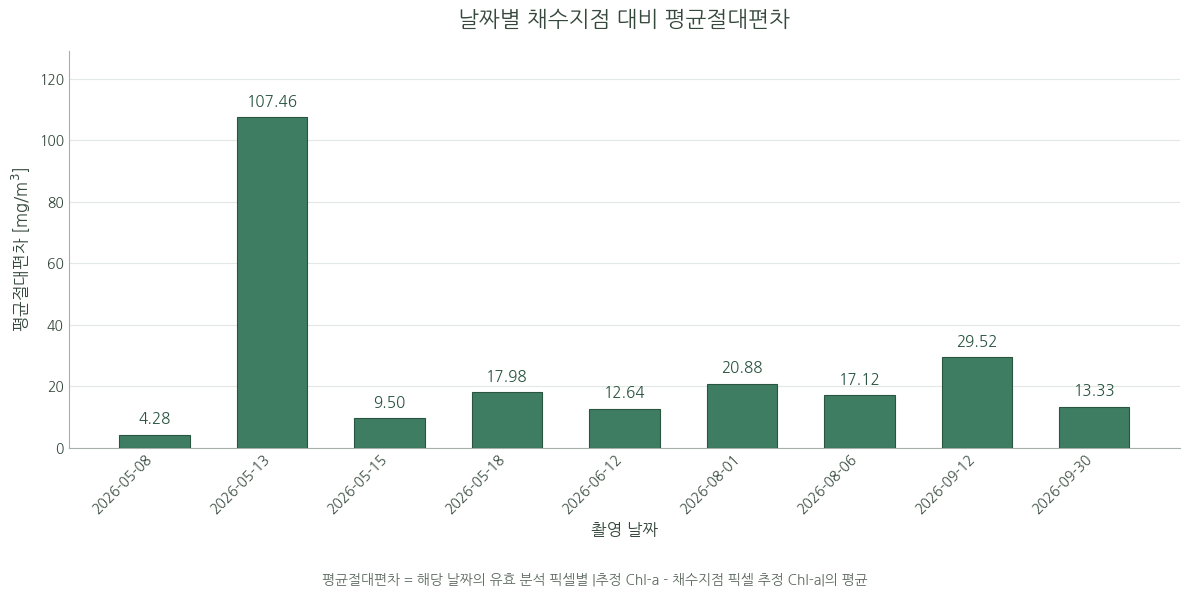

그래프와 평균절대편차 CSV 저장 완료


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from google.colab import files


# =========================================================
# 1. 저장 위치
# =========================================================

pixel_data_dir = (
    Path(OUTPUT_DIR)
    / "지도분석_픽셀자료"
)

graph_dir = (
    Path(OUTPUT_DIR)
    / "평균절대편차"
)

graph_dir.mkdir(
    parents=True,
    exist_ok=True
)

manifest_path = (
    pixel_data_dir
    / "픽셀자료_저장목록.csv"
)

if not manifest_path.exists():
    raise FileNotFoundError(
        "픽셀자료 저장목록이 없습니다. "
        "먼저 8단계 픽셀자료 저장 코드를 실행해 주세요."
    )

manifest = pd.read_csv(
    manifest_path,
    encoding="utf-8-sig"
)

if manifest.empty:
    raise ValueError(
        "저장된 픽셀자료가 없습니다."
    )


# =========================================================
# 2. 날짜·영상별 평균절대편차 계산
# =========================================================

records = []

for number, (_, item) in enumerate(
    manifest.iterrows(),
    start=1
):
    csv_path = (
        pixel_data_dir
        / item["CSV파일명"]
    )

    print(
        f"[{number}/{len(manifest)}] "
        f"{item['촬영시각_KST']} | "
        f"{item['영상명']}"
    )

    df = pd.read_csv(
        csv_path,
        encoding="utf-8-sig"
    )

    if "편차_mg_m3" not in df.columns:
        raise ValueError(
            f"{csv_path.name}에 "
            "'편차_mg_m3' 열이 없습니다."
        )

    deviation = pd.to_numeric(
        df["편차_mg_m3"],
        errors="coerce"
    )

    # 결측·비정상 값을 임의로 제외하지 않고 확인
    if not np.isfinite(deviation).all():
        raise ValueError(
            f"{csv_path.name}의 편차에 "
            "결측값 또는 비정상 값이 있습니다."
        )

    if len(deviation) == 0:
        raise ValueError(
            f"{csv_path.name}에 분석 픽셀이 없습니다."
        )

    if len(deviation) != int(item["분석픽셀수"]):
        raise ValueError(
            f"{csv_path.name}의 픽셀 수가 "
            "저장목록과 다릅니다."
        )

    # 픽셀별 편차의 절대값을 구한 뒤 평균
    mean_absolute_deviation = (
        deviation.abs().mean()
    )

    records.append({
        "촬영시각_KST": item["촬영시각_KST"],
        "영상명": item["영상명"],
        "분석픽셀수": len(deviation),
        "기준픽셀추정_Chla_mg_m3":
            item["기준픽셀추정_Chla_mg_m3"],
        "평균절대편차_mg_m3":
            float(mean_absolute_deviation)
    })


# =========================================================
# 3. 결과 표 정리
# =========================================================

mean_absolute_deviation_table = (
    pd.DataFrame(records)
    .sort_values(
        ["촬영시각_KST", "영상명"]
    )
    .reset_index(drop=True)
)

print("\n날짜별 평균절대편차")

display(
    mean_absolute_deviation_table.round(3)
)


# =========================================================
# 4. 그래프 날짜 표시
# =========================================================

date_labels = (
    mean_absolute_deviation_table["촬영시각_KST"]
    .astype(str)
    .str.slice(0, 10)
)

# 같은 날짜 영상이 여러 개이면 번호로 구분
duplicate_dates = date_labels.duplicated(
    keep=False
)

if duplicate_dates.any():
    date_numbers = (
        date_labels
        .groupby(date_labels, sort=False)
        .cumcount()
        .add(1)
    )

    graph_labels = [
        (
            f"{date}\n({number})"
            if duplicated
            else date
        )
        for date, number, duplicated in zip(
            date_labels,
            date_numbers,
            duplicate_dates
        )
    ]

else:
    graph_labels = date_labels.tolist()

mean_absolute_deviation_table["그래프표시"] = (
    graph_labels
)


# =========================================================
# 5. 그래프 색상 설정
# =========================================================

BAR_COLOR = "#3F7D63"
BAR_EDGE_COLOR = "#285440"
VALUE_COLOR = "#285440"

GRID_COLOR = "#E2E8E4"
AXIS_COLOR = "#A4B0A8"
TEXT_COLOR = "#35483C"

plt.rcParams["axes.unicode_minus"] = False


# =========================================================
# 6. 평균절대편차 그래프
# =========================================================

x = np.arange(
    len(mean_absolute_deviation_table)
)

values = (
    mean_absolute_deviation_table[
        "평균절대편차_mg_m3"
    ]
    .to_numpy()
)

fig, ax = plt.subplots(
    figsize=(12, 6)
)

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# 차분하고 깊이 있는 초록색 막대
ax.bar(
    x,
    values,
    width=0.60,
    color=BAR_COLOR,
    edgecolor=BAR_EDGE_COLOR,
    linewidth=0.8,
    zorder=3
)

# 막대 위 수치 표시
for position, value in zip(x, values):
    ax.annotate(
        f"{value:.2f}",
        xy=(position, value),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        color=VALUE_COLOR
    )

ax.set_title(
    "날짜별 채수지점 대비 평균절대편차",
    fontsize=16,
    color=TEXT_COLOR,
    pad=18
)

ax.set_xlabel(
    "촬영 날짜",
    fontsize=12,
    color=TEXT_COLOR
)

ax.set_ylabel(
    r"평균절대편차 [mg/m$^{3}$]",
    fontsize=12,
    color=TEXT_COLOR
)

ax.set_xticks(x)

ax.set_xticklabels(
    graph_labels,
    rotation=45,
    ha="right",
    fontsize=10
)

ax.set_ylim(
    0,
    max(
        float(values.max()) * 1.20,
        1.0
    )
)

ax.set_axisbelow(True)

ax.grid(
    axis="y",
    color=GRID_COLOR,
    linewidth=0.8
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color(AXIS_COLOR)
ax.spines["bottom"].set_color(AXIS_COLOR)

ax.tick_params(
    axis="both",
    length=0,
    colors=TEXT_COLOR
)

fig.text(
    0.5,
    0.02,
    "평균절대편차 = 해당 날짜의 유효 분석 픽셀별 "
    "|추정 Chl-a - 채수지점 픽셀 추정 Chl-a|의 평균",
    ha="center",
    fontsize=10,
    color="#5B685F"
)

fig.tight_layout(
    rect=[0, 0.07, 1, 1]
)


# =========================================================
# 7. 그래프·CSV 저장
# =========================================================

graph_path = (
    graph_dir
    / "날짜별_평균절대편차_초록색.png"
)

csv_path = (
    graph_dir
    / "날짜별_평균절대편차.csv"
)

fig.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

mean_absolute_deviation_table.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

plt.show()
plt.close(fig)

print("그래프와 평균절대편차 CSV 저장 완료")

files.download(str(graph_path))
files.download(str(csv_path))